In [ ]:
import wandb
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

api = wandb.Api()
run = api.run("my-ku-org/placemeent/9jw1nd1j") # 'wz-0728_084550' --> focus on this
# run_1 = api.run("my-ku-org/placemeent/5ympxbnu") # '0725_083903'
# run_2 = api.run("my-ku-org/placemeent/ba5ee0bz") # 'gnn-0724_132052'
# run_4 = api.run("my-ku-org/placemeent/b9opf3p7") #  '0729_085632'

In [ ]:
# keys=["global_step", "reward", "latency", "lb", "ru", "ER_adj"]
# r = run.history(keys=keys, samples=1000)
# r1 = run_1.history(keys=keys, samples=1000)
# r2 = run_2.history(keys=keys, samples=1000)
# r4 = run_4.history(keys=keys, samples=1000)

In [ ]:
r= run.scan_history(min_step=0, max_step=100_000)

In [ ]:
r = pd.DataFrame(r)
r

In [ ]:
r["global_step"]

In [ ]:
r["reward"]

In [ ]:
sum(r_["reward"] == 0)

In [ ]:
r["episode"]

In [ ]:
def episode_(df: pd.DataFrame):
    df = df.copy()
    df.loc[0, "episode"] = 0.0  # to interpolate correctly
    df["episode_"] = df["episode"].interpolate(method="linear").round()
    return df

def running_mean(x: pd.Series, n=100):
    return x.rolling(window=n, min_periods=1).mean()

def crop(df: pd.DataFrame, c: float):
    return df[df["episode_"] <= c]

In [ ]:
r = episode_(r)
# r1 = episode_(r1)
# r2 = episode_(r2)
# r4 = episode_(r4)

In [ ]:
r["episode_"].unique()

In [ ]:
# count how many times 0,1,2,3 appears in the episode_ column
r["episode_"].value_counts().sort_index()

In [ ]:
colors = ["#A12864", "#98DA4C", "#0000ff", "#ffff00"]
labels = ["LLM-MAPPO", "RSPPO", "GNN-DRL", "uDDRL"]

### I.a. cumulative reward

In [ ]:
key = "ER_adj"
at = np.inf #5000
plt.plot(crop(r, at)["episode_"][1:], running_mean(crop(r,at)[key], n=100)[1:], color=colors[0], label=labels[0])
# plt.plot(crop(r2, at)["episode_"][1:], running_mean(crop(r2,at)[key], n=100)[1:], color=colors[1], label=labels[1])
# plt.plot(crop(r3, at)["episode_"][1:], running_mean(crop(r3,at)[key], n=100)[1:], color=colors[2], label=labels[2])
# plt.plot(crop(r4, at)["episode_"][1:], running_mean(crop(r4,at)[key], n=100)[1:], color=colors[3], label=labels[3])
plt.legend()
plt.show()

### I.b. End-to-end latency

In [ ]:
key = "latency"
at = np.inf #5000
plt.plot(crop(r, at)["episode_"][1:], running_mean(crop(r,at)[key], n=100)[1:], color=colors[0], label=labels[0])
# plt.plot(crop(r2, at)["episode_"][1:], running_mean(crop(r2,at)[key], n=100)[1:], color=colors[1], label=labels[1])
# plt.plot(crop(r3, at)["episode_"][1:], running_mean(crop(r3,at)[key], n=100)[1:], color=colors[2], label=labels[2])
# plt.plot(crop(r4, at)["episode_"][1:], running_mean(crop(r4,at)[key], n=100)[1:], color=colors[3], label=labels[3])
plt.legend()
plt.show()

### I.c. QoS load balancing index

In [ ]:
key = "lb"
at = np.inf #5000
plt.plot(crop(r, at)["episode_"][1:], running_mean(crop(r,at)[key], n=100)[1:], color=colors[0], label=labels[0])
# plt.plot(crop(r2, at)["episode_"][1:], running_mean(crop(r2,at)[key], n=100)[1:], color=colors[1], label=labels[1])
# plt.plot(crop(r3, at)["episode_"][1:], running_mean(crop(r3,at)[key], n=100)[1:], color=colors[2], label=labels[2])
# plt.plot(crop(r4, at)["episode_"][1:], running_mean(crop(r4,at)[key], n=100)[1:], color=colors[3], label=labels[3]) 
plt.legend()
plt.show()

### I.d. Resource Utilization(%)

In [ ]:
key = "ru"
at = np.inf #5000
plt.plot(crop(r, at)["episode_"][1:], running_mean(crop(r,at)[key], n=100)[1:], color=colors[0], label=labels[0])
# plt.plot(crop(r2, at)["episode_"][1:], running_mean(crop(r2,at)[key], n=100)[1:], color=colors[1], label=labels[1])
# plt.plot(crop(r3, at)["episode_"][1:], running_mean(crop(r3,at)[key], n=100)[1:], color=colors[2], label=labels[2])
plt.legend()
plt.show()

### I.d. SLA violation rate(%)

In [ ]:
# count 0 pre rewards
sum(r["reward"] == 0)

In [ ]:
r[r['reward'] < 9.99].groupby('episode_').size()

In [ ]:
r[r['reward'] < 1].groupby('episode_').size().plot()

# etc...

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import json
import os
def load_summary_files(directory, run_name):
    summaries = []
    for filename in os.listdir(directory):
        if filename.startswith(f"{run_name}-summary-") and filename.endswith(".json"):
            with open(os.path.join(directory, filename), 'r') as f:
                summaries.append(json.load(f))
    return summaries
def extract_metrics(summaries):
    metrics = []
    slas = []
    arrival_rates = []
    for summary in summaries:
        num_reqs = summary["num_reqs"]
        if num_reqs % 5 == 0:
            m_l = summary["latency"][0]
            m_lb = summary["lb"][0]
            m_ru = summary["ru"][0]
            s_l = summary["latency"][1]
            s_lb = summary["lb"][1]
            s_ru = summary["ru"][1]
            metrics.append((m_l, m_lb, m_ru, s_l, s_lb, s_ru))
            slas.append(summary["sla_violation"]/summary["ep_step"])
            arrival_rates.append(num_reqs)
    
    # use the index of arrival_rates to sort metrics and slas
    sorted_indices = np.argsort(arrival_rates)
    metrics = [metrics[i] for i in sorted_indices]
    slas = [slas[i] for i in sorted_indices]
    arrival_rates = [arrival_rates[i] for i in sorted_indices]
    return metrics, slas, arrival_rates

def extract_metrics_nms(summaries):
    metrics = []
    slas = []
    nmss = []
    for summary in summaries:
        nms = summary["nms"]
        if nms % 5 == 0:
            m_l = summary["latency"][0]
            m_lb = summary["lb"][0]
            m_ru = summary["ru"][0]
            s_l = summary["latency"][1]
            s_lb = summary["lb"][1]
            s_ru = summary["ru"][1]
            metrics.append((m_l, m_lb, m_ru, s_l, s_lb, s_ru))
            slas.append(summary["sla_violation"]/summary["ep_step"])
            nmss.append(nms)
    
    # use the index of arrival_rates to sort metrics and slas
    sorted_indices = np.argsort(nmss)
    metrics = [metrics[i] for i in sorted_indices]
    slas = [slas[i] for i in sorted_indices]
    nmss = [nmss[i] for i in sorted_indices]
    return metrics, slas, nmss


In [45]:
def plot_metrics(arrival_rates, metrics, slas):
    m_l, m_lb, m_ru, _,_,_ = zip(*metrics[0])
    m_l1, m_lb1, m_ru1, _,_,_ = zip(*metrics[1])

    arrival_rates1 = arrival_rates[1]
    arrival_rates = arrival_rates[0]

    slas1 = slas[1]
    slas = slas[0]

    np.save("o/arrival.npy", {
        "arrival_rates": arrival_rates,
        "arrival_rates1": arrival_rates1,
        "latency_wz_toporag": m_l,
        "latency_wo_toporag": m_l1,
        "lb_wz_toporag": m_lb,
        "lb_wo_toporag": m_lb1,
        "ru_wz_toporag": m_ru,
        "ru_wo_toporag": m_ru1,
        "slas_wz_toporag": slas,
        "slas_wo_toporag": slas1
        }, allow_pickle=True)

    
    plt.figure(figsize=(12, 8))
    
    # Mean Latency
    plt.subplot(3, 2, 1)
    plt.plot(arrival_rates, m_l, marker='o', label='LLM-MAPPO')
    plt.plot(arrival_rates1, m_l1, marker='o', label='LLM-MAPPO (wo TopoRAG)')
    plt.xlabel('Arrival Rate (req/s)')
    plt.ylabel('Mean Latency')
    plt.grid()
    plt.legend()
    
    # Mean Load Balancing
    plt.subplot(3, 2, 2)
    plt.plot(arrival_rates, m_lb, marker='o', label='LLM-MAPPO')
    plt.plot(arrival_rates1, m_lb1, marker='o', label='LLM-MAPPO (wo TopoRAG)')
    plt.xlabel('Arrival Rate (req/s)')
    plt.ylabel('Mean Load Balancing')
    plt.grid()
    plt.legend()
    
    # Mean Resource Utilization
    plt.subplot(3, 2, 3)
    plt.plot(arrival_rates, m_ru, marker='o', label='LLM-MAPPO')
    plt.plot(arrival_rates1, m_ru1, marker='o', label='LLM-MAPPO (wo TopoRAG)')
    plt.xlabel('Arrival Rate (req/s)')
    plt.ylabel('Mean Resource Utilization')
    plt.grid()
    plt.legend()


    # sla violations
    plt.subplot(3, 2, 4)
    plt.plot(arrival_rates, slas, marker='o', label='LLM-MAPPO')
    plt.plot(arrival_rates1, slas1, marker='o', label='LLM-MAPPO (wo TopoRAG)')
    plt.xlabel('Arrival Rate (req/s)')
    plt.ylabel('Total SLA Violations')
    plt.grid()
    plt.legend()

    # Show plots
    plt.tight_layout()
    plt.show()

In [46]:
def plot_metrics_bar(arrival_rates, metrics, slas):
    m_l, m_lb, m_ru, _,_,_ = zip(*metrics[0])
    m_l1, m_lb1, m_ru1, _,_,_ = zip(*metrics[1])

    arrival_rates1 = arrival_rates[1]
    arrival_rates = arrival_rates[0]

    slas1 = slas[1]
    slas = slas[0]

    # Ensure arrival_rates and other x-axes are numpy arrays
    arrival_rates = np.array(arrival_rates)
    arrival_rates1 = np.array(arrival_rates1)

    np.save("o/nms.npy", {
        "arrival_rates": arrival_rates,
        "arrival_rates1": arrival_rates1,
        "latency_wz_toporag": m_l,
        "latency_wo_toporag": m_l1,
        "lb_wz_toporag": m_lb,
        "lb_wo_toporag": m_lb1,
        "ru_wz_toporag": m_ru,
        "ru_wo_toporag": m_ru1,
        "slas_wz_toporag": slas,
        "slas_wo_toporag": slas1
    }, allow_pickle=True)

    bar_width = 0.35
    x = np.arange(len(arrival_rates))  # For positioning bars

    plt.figure(figsize=(12, 8))

    # Mean Latency
    plt.subplot(3, 2, 1)
    plt.bar(x - bar_width/2, m_l, width=bar_width, label='LLM-MAPPO')
    plt.bar(x + bar_width/2, m_l1, width=bar_width, label='LLM-MAPPO (wo TopoRAG)')
    plt.xticks(x, arrival_rates)
    plt.xlabel('N_MS')
    plt.ylabel('Mean Latency')
    plt.grid(True, axis='y')
    plt.legend()

    # Mean Load Balancing
    plt.subplot(3, 2, 2)
    plt.bar(x - bar_width/2, m_lb, width=bar_width, label='LLM-MAPPO')
    plt.bar(x + bar_width/2, m_lb1, width=bar_width, label='LLM-MAPPO (wo TopoRAG)')
    plt.xticks(x, arrival_rates)
    plt.xlabel('N_MS')
    plt.ylabel('Mean Load Balancing')
    plt.grid(True, axis='y')
    plt.legend()

    # Mean Resource Utilization
    plt.subplot(3, 2, 3)
    plt.bar(x - bar_width/2, m_ru, width=bar_width, label='LLM-MAPPO')
    plt.bar(x + bar_width/2, m_ru1, width=bar_width, label='LLM-MAPPO (wo TopoRAG)')
    plt.xticks(x, arrival_rates)
    plt.xlabel('N_MS')
    plt.ylabel('Mean Resource Utilization')
    plt.grid(True, axis='y')
    plt.legend()

    # SLA Violations
    plt.subplot(3, 2, 4)
    plt.bar(x - bar_width/2, slas, width=bar_width, label='LLM-MAPPO')
    plt.bar(x + bar_width/2, slas1, width=bar_width, label='LLM-MAPPO (wo TopoRAG)')
    plt.xticks(x, arrival_rates)
    plt.xlabel('N_MS')
    plt.ylabel('Total SLA Violations')
    plt.grid(True, axis='y')
    plt.legend()

    # Show plots
    plt.tight_layout()
    plt.show()


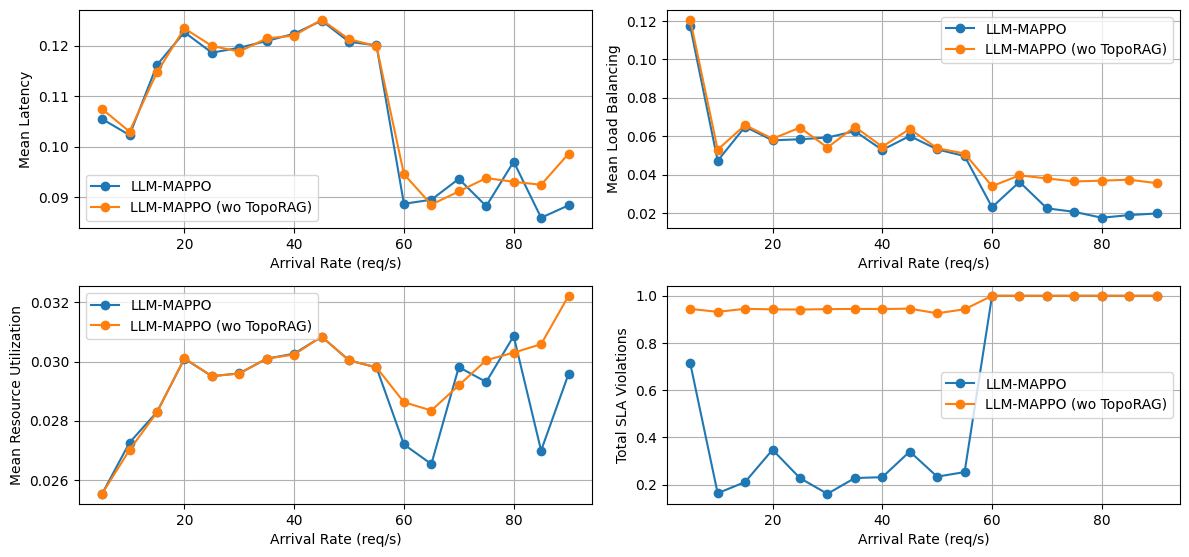

In [50]:
summaries = load_summary_files(directory="out", run_name="0729_085632")
metrics, slas, arrival_rates = extract_metrics(summaries)

summaries = load_summary_files(directory="out-notoporag", run_name="0729_085632")
metrics1, slas1, arrival_rates1 = extract_metrics(summaries)

plot_metrics([arrival_rates, arrival_rates1], [metrics, metrics1], [slas, slas1])

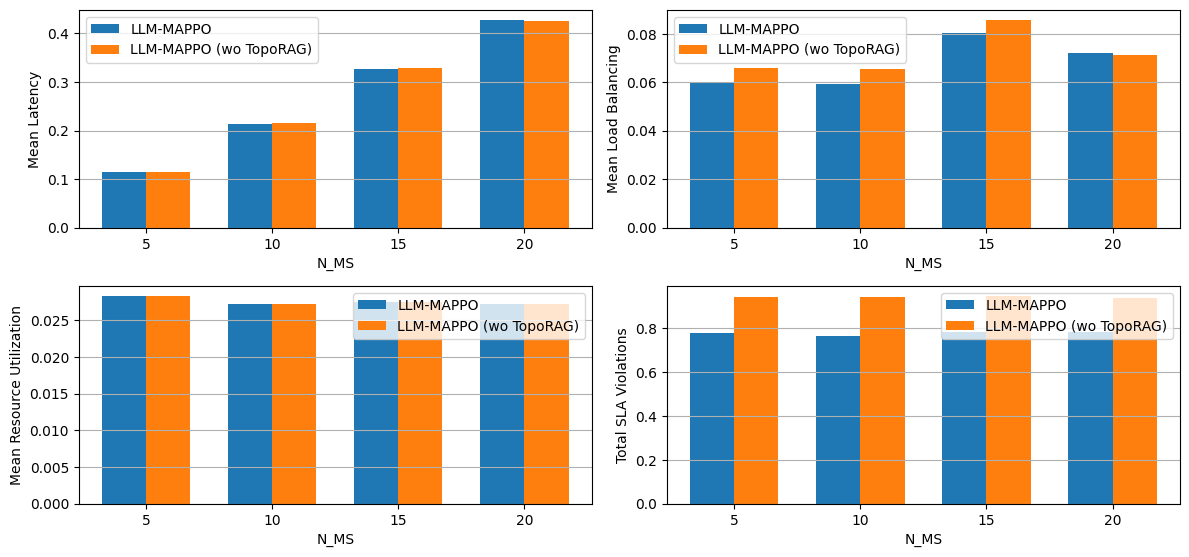

In [51]:
summaries = load_summary_files(directory="out-nms", run_name="0729_085632")
metrics, slas, nms = extract_metrics_nms(summaries)

summaries = load_summary_files(directory="out-nms-notoporag", run_name="0729_085632")
metrics1, slas1, nms1 = extract_metrics_nms(summaries)

plot_metrics_bar([nms, nms1], [metrics, metrics1], [slas, slas1])